### Load EKG Datasets

We will load the two CSV datasets:
* Run 1 as `df_200sps` (200 samples per second)
* Run 2 as `df_50sps` (50 samples per second)

In [21]:
import pandas as pd

# Load the datasets

df_200sps = pd.read_csv('https://raw.githubusercontent.com/claireslgreen/bioelectronics-lab-1/refs/heads/main/ENSG%20127%20Lab%201%20Run%201.csv')
df_50sps = pd.read_csv('https://raw.githubusercontent.com/claireslgreen/bioelectronics-lab-1/refs/heads/main/ENSG%20127%20Lab%201%20Run%202.csv')

# print("200 sps (Run 1) Columns & Shape:")
# print(df_200sps.info())
# display(df_200sps.head())

# print("\n50 sps (Run 2) Columns & Shape:")
# print(df_50sps.info())
# display(df_50sps.head())

### Verify Sampling Periods and Plot EKG Waveform
We calculate the sampling period ($T = 1/f_s$) for both datasets and plot a segment of the 200 sps EKG data to identify a representative waveform.

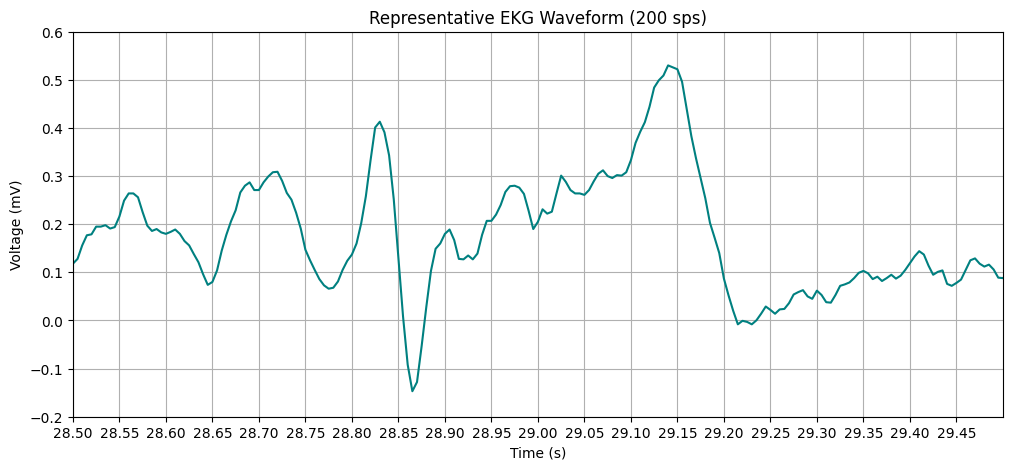

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate sampling periods
# dt_200sps = df_200sps['Time (s) Run 1'].dropna().diff().median()
# dt_50sps = df_50sps['Time (s) Run 2'].dropna().diff().median()

# print(f"Calculated sampling period for Run 1 (200sps): {dt_200sps:.5f} s (Expected: {1/200:.5f} s)")
# print(f"Calculated sampling period for Run 2 (50sps): {dt_50sps:.5f} s (Expected: {1/50:.5f} s)")

# Plot a 3-second window of the 200 sps data to find a clear waveform
# Let's filter out rows where Voltage is NaN
clean_200sps = df_200sps.dropna(subset=['Voltage (mV) Run 1'])

plt.figure(figsize=(12, 5))
plt.plot(clean_200sps['Time (s) Run 1'], clean_200sps['Voltage (mV) Run 1'], label='EKG (200sps)', color='teal')
plt.title('Representative EKG Waveform (200 sps)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (mV)')
plt.xlim(28.5, 29.5) # Zoom into a 5-second window
plt.ylim(-0.2, 0.6)
plt.grid(True)
# plt.legend()
# plt.xticks(np.arange(27, 28, 0.5))
plt.xticks(np.arange(28.5, 29.5, 0.05))
plt.show()

### Zooming in and Measuring EKG Intervals
We will zoom into the interval between **28.6 and 29.3 seconds** to examine a single clear, representative EKG heartbeat cycle.

We will mark and measure:
1. **PR Interval**: From the start of the P wave to the start of the QRS complex (Q wave).
2. **QRS Complex**: From the onset of the Q wave to the end of the S wave (J-point).
3. **QT Interval**: From the onset of the QRS complex to the end of the T wave.

Measured Intervals (in seconds):
- PR Interval:  0.135 s
- QRS Duration: 0.110 s
- QT Interval:  0.435 s


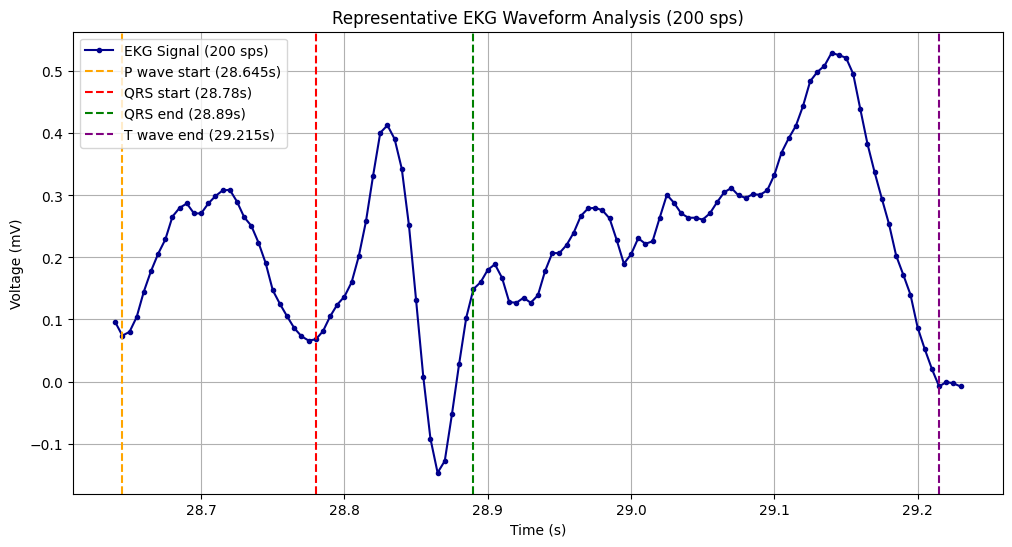

In [23]:
import matplotlib.pyplot as plt

# Filter data to zoom in on a single heartbeat (around 28.6 to 29.3 seconds)
heartbeat = clean_200sps[(clean_200sps['Time (s) Run 1'] >= 28.64) & (clean_200sps['Time (s) Run 1'] <= 29.23)]

plt.figure(figsize=(12, 6))
plt.plot(heartbeat['Time (s) Run 1'], heartbeat['Voltage (mV) Run 1'], label='EKG Signal (200 sps)', color='darkblue', marker='o', markersize=3)

# Let's define the points based on visual inspection of the plotted data:
# P wave start: ~28.64s
# QRS start (Q-onset): ~28.77s
# QRS end (S-offset / J-point): ~28.89s
# T wave end (T-offset): ~29.21s

t_p_start = 28.645
t_qrs_start = 28.78
t_qrs_end = 28.89
t_t_end = 29.215

# Plot vertical marker lines for visual verification
plt.axvline(x=t_p_start, color='orange', linestyle='--', label=f'P wave start ({t_p_start}s)')
plt.axvline(x=t_qrs_start, color='red', linestyle='--', label=f'QRS start ({t_qrs_start}s)')
plt.axvline(x=t_qrs_end, color='green', linestyle='--', label=f'QRS end ({t_qrs_end}s)')
plt.axvline(x=t_t_end, color='purple', linestyle='--', label=f'T wave end ({t_t_end}s)')

# Calculate interval time durations
pr_interval = t_qrs_start - t_p_start
qrs_duration = t_qrs_end - t_qrs_start
qt_interval = t_t_end - t_qrs_start

print(f"Measured Intervals (in seconds):")
print(f"- PR Interval:  {pr_interval:.3f} s")
print(f"- QRS Duration: {qrs_duration:.3f} s")
print(f"- QT Interval:  {qt_interval:.3f} s")

plt.title('Representative EKG Waveform Analysis (200 sps)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (mV)')
plt.grid(True)
plt.legend()
plt.show()

###  Magnitude of the QRS complex and P wave
[parts of an ECG wave](https://litfl.com/p-wave-ecg-library/)

The P-wave represents the activation (depolarization) of the atria, while the QRS complex represents the depolarization of the ventricles. The atria only need to pump blood into the ventricles, while the ventricles have to pump blood throughout the whole body. Thus, the ventricles have significantly more muscle mass, so they generate a larger electrical potential than the atria. This is why the magnitude of the QRS complex is larger than the magnitude of the P-wave.

In [24]:
# isolate p wave and QRS complex
p_wave = clean_200sps[(clean_200sps['Time (s) Run 1'] >= 28.645) & (clean_200sps['Time (s) Run 1'] <= 28.78)]
qrs = clean_200sps[(clean_200sps['Time (s) Run 1'] >= 28.78) & (clean_200sps['Time (s) Run 1'] <= 28.89)]

# find baseline voltage
flat_section = clean_200sps[(clean_200sps['Time (s) Run 1'] >= 29.22) & (clean_200sps['Time (s) Run 1'] <= 29.5)]
baseline_voltage = flat_section['Voltage (mV) Run 1'].mean()

# find baseline-to-peak for each
mag_p = p_wave['Voltage (mV) Run 1'].max() - baseline_voltage
mag_qrs = qrs['Voltage (mV) Run 1'].max() - baseline_voltage

# find peak-to-peak for each
mag_p_2 = p_wave['Voltage (mV) Run 1'].max() - p_wave['Voltage (mV) Run 1'].min()
mag_qrs_2 = qrs['Voltage (mV) Run 1'].max() - qrs['Voltage (mV) Run 1'].min()

# print values
print(f"Baseline voltage:  {baseline_voltage:.3f} mV")
print(f"Baseline-to-peak:")
print(f"- P wave:  {mag_p:.3f} mV")
print(f"- QRS complex: {mag_qrs:.3f} mV")
print(f"Peak-to-peak:")
print(f"- P wave:  {mag_p_2:.3f} mV")
print(f"- QRS complex: {mag_qrs_2:.3f} mV")


Baseline voltage:  0.075 mV
Baseline-to-peak:
- P wave:  0.234 mV
- QRS complex: 0.338 mV
Peak-to-peak:
- P wave:  0.243 mV
- QRS complex: 0.560 mV


### Average Heart Rate

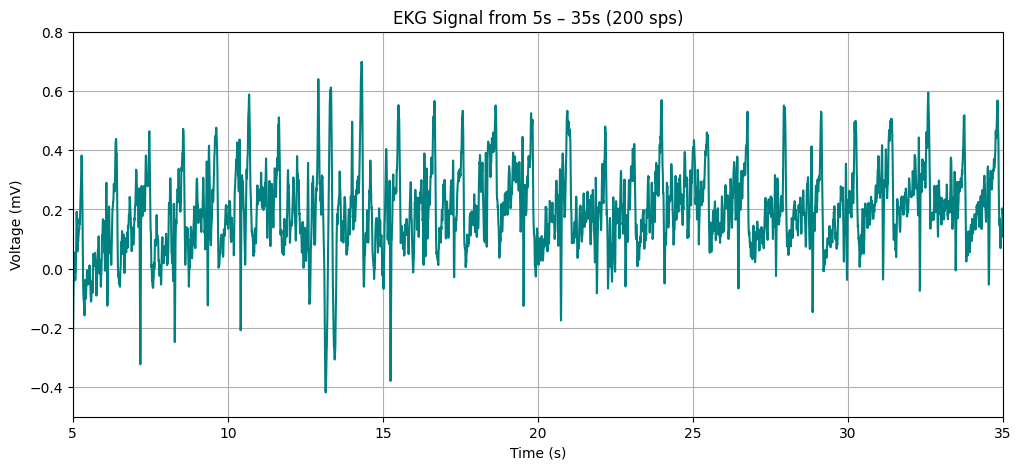

Average Heart Rate: 60.9 BPM


In [25]:
from scipy.signal import find_peaks

plt.figure(figsize=(12, 5))
plt.plot(clean_200sps['Time (s) Run 1'], clean_200sps['Voltage (mV) Run 1'], label='EKG (200sps)', color='teal')
plt.title('EKG Signal from 5s – 35s (200 sps)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (mV)')
plt.xlim(5, 35) # smaller time window
plt.ylim(-0.5, 0.8)
plt.grid(True)
plt.show()

# extract 30 seconds without noisy beginning
beats_avg = clean_200sps[(clean_200sps['Time (s) Run 1'] >= 5) & (clean_200sps['Time (s) Run 1'] <= 35)]

# Use a height that catches the main peaks but avoids baseline noise,
# and a distance of 100 samples (0.5 seconds) to prevent double-counting noise within the same beat
peaks, _ = find_peaks(beats_avg['Voltage (mV) Run 1'], height=0.35, distance=100)

# Extract the times at which these peaks occur
peak_times = beats_avg['Time (s) Run 1'].iloc[peaks].values

# Calculate the time differences between consecutive peaks (R-R intervals)
rr_intervals = np.diff(peak_times)

# Calculate average heart rate in BPM (60 seconds / average R-R interval)
average_bpm = 60 / rr_intervals.mean()

print(f"Average Heart Rate: {average_bpm:.1f} BPM")


### Power Spectral Analysis

The spike at 0.1 Hz is most likely from interactions between the skin and the electrode. The spike just under 1 Hz is the primary cardiac pulse, which lines up with the average bpm. The spikes higher up represent noise in the data.

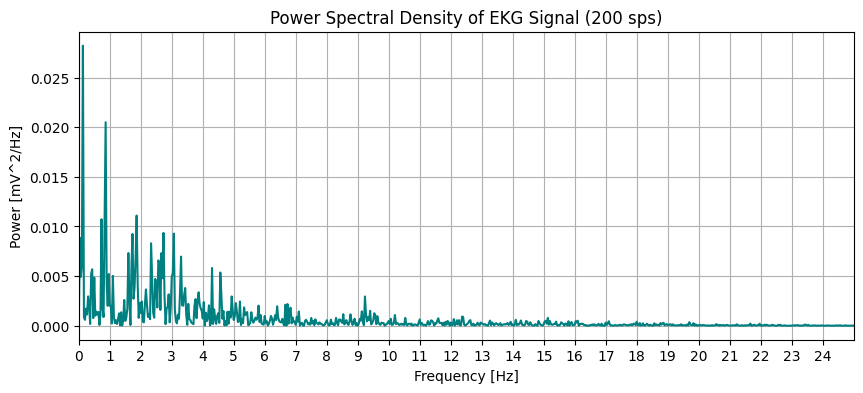

In [26]:
from scipy import signal
from numpy.fft import fft

# Define the data and parameters
x = beats_avg['Voltage (mV) Run 1'].values  # EKG voltage data
dt = 1 / 200  # Sampling interval (200 sps)
N = x.shape[0]  # Total number of data points
T = N * dt  # Total duration of the recording in seconds

# Compute the Fourier transform
# Subtracting the mean removes the DC offset (baseline drift) so it doesn't skew the 0 Hz power
xf = fft(x - x.mean())

# Compute the Power Spectral Density (Sxx)
Sxx = 2 * dt ** 2 / T * (xf * xf.conj())

# Ignore negative frequencies (keep only the first half of the array)
Sxx = Sxx[:int(len(x) / 2)]

# Construct the frequency axis
df = 1 / T  # Frequency resolution
fNQ = 1 / dt / 2  # Nyquist frequency (half the sampling rate: 100 Hz)
faxis = np.arange(len(Sxx)) * df

# 6. Plot the Power Spectral Density
plt.figure(figsize=(10, 4))
plt.plot(faxis, Sxx.real, color='teal')
plt.xlim([0, 25]) # no visible peaks past this point
plt.xlabel('Frequency [Hz]')
plt.ylabel('Power [mV^2/Hz]')
plt.title('Power Spectral Density of EKG Signal (200 sps)')
plt.grid(True)
plt.xticks(np.arange(0, 25, 1))
plt.show()

### 50 sps data

The 50 sps data has less noise. The 50sps data is worse than the 200 sps data. The QRS complex is too fast to be reliably measured using 50 sps.

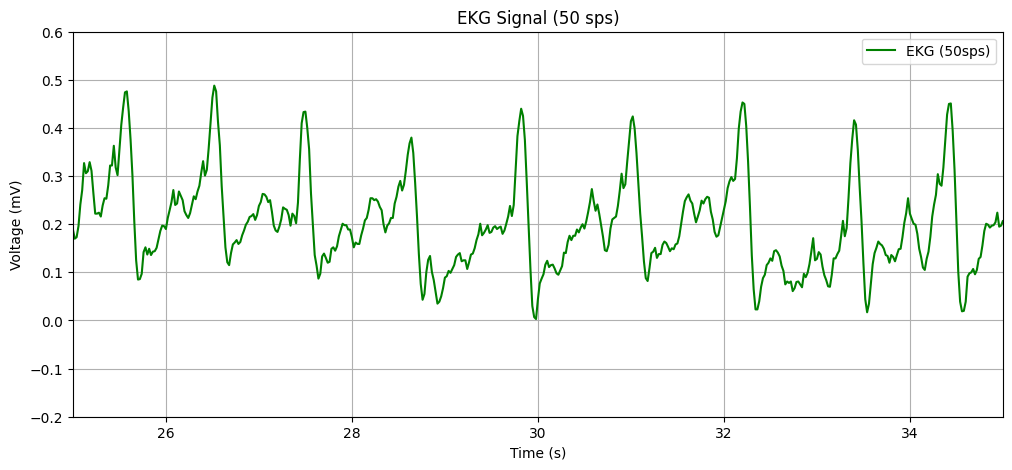

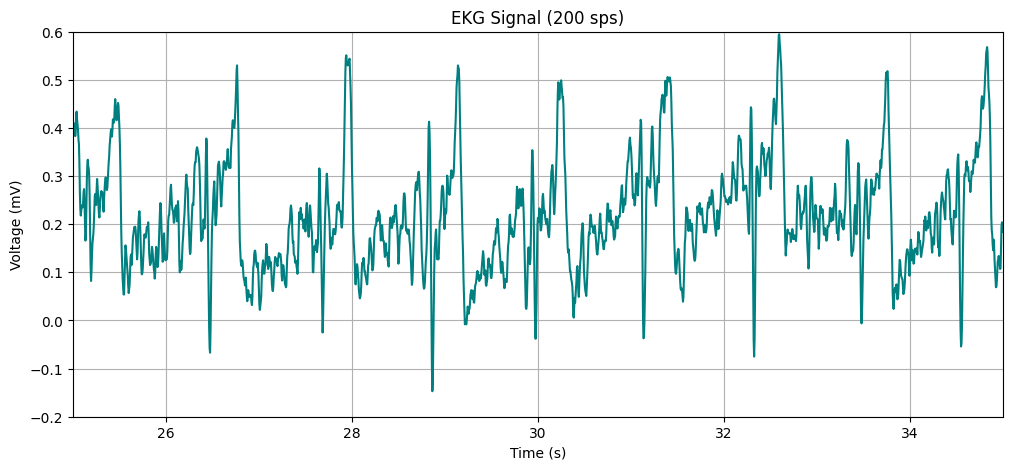

In [27]:
clean_50sps = df_50sps.dropna(subset=['Voltage (mV) Run 2'])

plt.figure(figsize=(12, 5))
plt.plot(clean_50sps['Time (s) Run 2'], clean_50sps['Voltage (mV) Run 2'], label='EKG (50sps)', color='green')
plt.title('EKG Signal (50 sps)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (mV)')
plt.xlim(25, 35) # Zoom in
plt.ylim(-0.2, 0.6)
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(clean_200sps['Time (s) Run 1'], clean_200sps['Voltage (mV) Run 1'], label='EKG (200sps)', color='teal')
plt.title('EKG Signal (200 sps)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (mV)')
plt.xlim(25, 35) # Zoom in
plt.ylim(-0.2, 0.6)
plt.grid(True)
plt.show()

